# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:** Muhammad Taraz  
- **Student ID:** 023-24-0259  
- **Section:** H  
- **GitHub Profile:** https://github.com/Muhammad-taraz  
- **Kaggle Profile:** https://www.kaggle.com/MuhammadTaraz

- **Dataset:** Mall Customers (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

### Before You Start
- This lab does not reteach K-Means. It makes you use and test what you saw in the lecture. Each task gives the steps, not the code; the **Key definitions** table in each Part lists what you need.
- There is **no target column**: no train/test split and no accuracy. Judge every result by distances, silhouette, plots and common sense.
- Use `SEED = 42` everywhere. Write 1–3 lines of interpretation under every table and plot. A plot without an explanation earns no marks.
- Place `Mall_Customers.csv` in the same folder as this notebook (or upload it to Colab).
- Time: about 2 hours 15 minutes of work. Use the remaining time to finish answers, run the notebook top to bottom and submit.

---

## Part 0 — Setup and First Look (10 minutes)

Load the data and look at it before you cluster anything.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |

**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [1]:
# Imports and fixed random seed
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

SEED = 42
np.random.seed(SEED)

print("Libraries imported successfully.")
print("Random seed:", SEED)

Libraries imported successfully.
Random seed: 42


### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.

In [2]:
# Task 0.1: Load the dataset and inspect it
# Keep Mall_Customers.csv in the same folder as this notebook.
csv_path = Path("Mall_Customers.csv")

if not csv_path.exists():
    raise FileNotFoundError(
        "Mall_Customers.csv was not found. Download it from the Kaggle dataset "
        "linked in the Student Information section, extract the ZIP file, and "
        "place Mall_Customers.csv beside this notebook."
    )

df = pd.read_csv(csv_path)
df = df.rename(columns={
    "Annual Income (k$)": "Income",
    "Spending Score (1-100)": "Spending"
})

required_columns = ["CustomerID", "Gender", "Age", "Income", "Spending"]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing these required columns: {missing_columns}")

print("Dataset shape:", df.shape)
print("\\nMissing values in each column:")
print(df.isna().sum())
print("\\nTotal missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("\\nGender counts:")
print(df["Gender"].value_counts())
print("\\nDescriptive statistics:")
display(df[["Age", "Income", "Spending"]].describe())

Dataset shape: (200, 5)
\nMissing values in each column:
CustomerID    0
Gender        0
Age           0
Income        0
Spending      0
dtype: int64
\nTotal missing values: 0
Duplicate rows: 0
\nGender counts:
Gender
Female    112
Male       88
Name: count, dtype: int64
\nDescriptive statistics:


,Age,Income,Spending
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


### Task 0.2 — Look at the data before clustering

Use your eyes first.

1. Draw one scatter plot of Spending vs Income, with axis labels and a title.

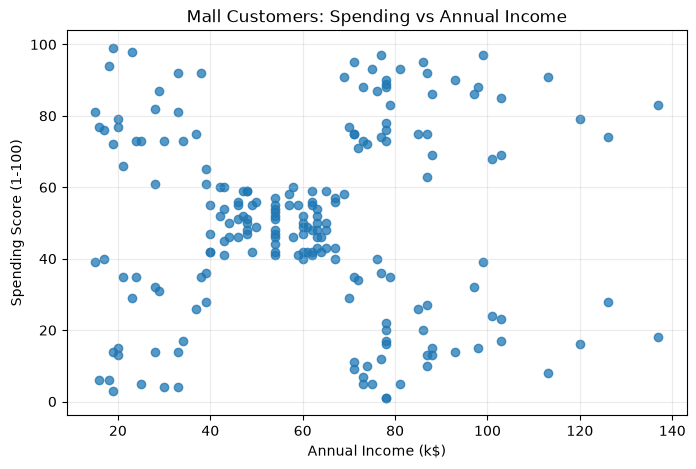

Interpretation: The scatter plot shows customer groups mainly by their income and spending behaviour. The separation is not perfectly clear for every customer.


In [3]:
# Task 0.2: Scatter plot before clustering
plt.figure(figsize=(8, 5))
plt.scatter(df["Income"], df["Spending"], alpha=0.75)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Mall Customers: Spending vs Annual Income")
plt.grid(alpha=0.25)
plt.show()

print("Interpretation: The scatter plot shows customer groups mainly by their income "
      "and spending behaviour. The separation is not perfectly clear for every customer.")

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye? Describe them in one line each (e.g. 'high income, low spending').

(b) Why can we not use accuracy or a train/test split to judge a clustering result?

**Your answers:**

(a) The scatter plot gives a visual idea of customer groups. I can see broad patterns, including customers with low income and low spending customers with high income and high spending and customers whose spending is low despite higher income. The exact group boundaries are not clear from the plot so K-Means will help make the grouping more systematic.

(b) This is learning so the dataset has no correct target labels to compare against. Accuracy needs known answers. A train/test split is also unnecessary because the task is to find groups, in the data not predict a target column.

---

## Part 1 — K-Means From Scratch (30 minutes)

In the lecture you did K-Means by hand. Here you turn those steps into code and check your own function against scikit-learn. Using `KMeans()` inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: \|x - m\|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |

### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: `np.abs(x[:, None] - m[None, :])` has shape (9, 2).
- Cluster of each point: `dist.argmin(axis=1)`.

In [4]:
# Task 1.1: Lecture Example 1, one feature
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
centroids = np.array([4.0, 11.0])

iteration = 0
while True:
    iteration += 1
    distances = np.abs(x[:, None] - centroids[None, :])
    labels = distances.argmin(axis=1)

    new_centroids = centroids.copy()
    for k in range(2):
        if np.any(labels == k):
            new_centroids[k] = x[labels == k].mean()

    print(f"Iteration {iteration}")
    for k in range(2):
        print(f"  Cluster C{k+1}:", x[labels == k].astype(int).tolist())
    print("  New centroids:", new_centroids)

    if np.allclose(new_centroids, centroids):
        centroids = new_centroids
        break
    centroids = new_centroids

final_distances = np.abs(x - centroids[labels])
inertia_example = float(np.sum(final_distances ** 2))
print("\\nFinal centroids:", centroids)
print("Final inertia:", inertia_example)
print("Lecture check: expected centroids [7, 25] and inertia 150.")

Iteration 1
  Cluster C1: [2, 4, 3]
  Cluster C2: [10, 12, 20, 30, 11, 25]
  New centroids: [ 3. 18.]
Iteration 2
  Cluster C1: [2, 4, 10, 3]
  Cluster C2: [12, 20, 30, 11, 25]
  New centroids: [ 4.75 19.6 ]
Iteration 3
  Cluster C1: [2, 4, 10, 12, 3, 11]
  Cluster C2: [20, 30, 25]
  New centroids: [ 7. 25.]
Iteration 4
  Cluster C1: [2, 4, 10, 12, 3, 11]
  Cluster C2: [20, 30, 25]
  New centroids: [ 7. 25.]
\nFinal centroids: [ 7. 25.]
Final inertia: 150.0
Lecture check: expected centroids [7, 25] and inertia 150.


### Task 1.2 — Your own K-Means function vs scikit-learn

Turn your loop into a function, then show it gives the same answer as scikit-learn.

1. Write `my_kmeans(X, init_centroids, max_iter=100)` that works for any number of features and returns labels, centroids, inertia and the number of iterations. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
2. Use X2 = Income and Spending (200 x 2) with the first 5 rows as starting centroids. Run `my_kmeans` and `KMeans(n_clusters=5, init=<the same 5 rows>, n_init=1, tol=0, algorithm='lloyd')`, then compare the inertia and the centroids.

In [5]:
# Task 1.2: Write K-Means from scratch. Do not call sklearn KMeans here.
def my_kmeans(X, init_centroids, max_iter=100):
    X = np.asarray(X, dtype=float)
    centroids = np.asarray(init_centroids, dtype=float).copy()

    if X.ndim != 2 or centroids.ndim != 2:
        raise ValueError("X and init_centroids must be 2D arrays.")
    if X.shape[1] != centroids.shape[1]:
        raise ValueError("X and centroids must have the same number of features.")

    for iteration in range(1, max_iter + 1):
        # Euclidean distance from each row to each centroid
        distances = np.sqrt(((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2))
        labels = distances.argmin(axis=1)

        new_centroids = centroids.copy()
        for k in range(len(centroids)):
            if np.any(labels == k):
                new_centroids[k] = X[labels == k].mean(axis=0)

        if np.allclose(new_centroids, centroids):
            centroids = new_centroids
            break
        centroids = new_centroids

    # Reassign using the final centroids and calculate final inertia
    distances = np.sqrt(((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2))
    labels = distances.argmin(axis=1)
    inertia = float(np.sum((X - centroids[labels]) ** 2))
    return labels, centroids, inertia, iteration

example_X = x.reshape(-1, 1)
example_labels, example_centroids, example_inertia, example_iterations = my_kmeans(
    example_X, np.array([[4.0], [11.0]])
)
print("Example 1 from scratch")
print("Centroids:", np.sort(example_centroids.ravel()))
print("Inertia:", example_inertia)
print("Iterations:", example_iterations)
assert np.allclose(np.sort(example_centroids.ravel()), [7, 25])
assert np.isclose(example_inertia, 150)

Example 1 from scratch
Centroids: [ 7. 25.]
Inertia: 150.0
Iterations: 4


In [6]:
# Compare the scratch function with scikit-learn on Income and Spending
X2 = df[["Income", "Spending"]].to_numpy(dtype=float)
initial_centroids = X2[:5].copy()

my_labels, my_centroids, my_inertia, my_iterations = my_kmeans(
    X2, initial_centroids, max_iter=100
)

sk_model = KMeans(
    n_clusters=5,
    init=initial_centroids,
    n_init=1,
    tol=0,
    algorithm="lloyd",
    max_iter=100,
    random_state=SEED
)
sk_labels = sk_model.fit_predict(X2)

print("Scratch K-Means inertia:", my_inertia)
print("Scikit-learn inertia:", sk_model.inertia_)
print("Absolute inertia difference:", abs(my_inertia - sk_model.inertia_))
print("Scratch iterations:", my_iterations)
print("\\nScratch centroids (sorted by Income):")
print(my_centroids[np.argsort(my_centroids[:, 0])])
print("\\nScikit-learn centroids (sorted by Income):")
print(sk_model.cluster_centers_[np.argsort(sk_model.cluster_centers_[:, 0])])
print("\\nNote: cluster numbers can be different because cluster labels are arbitrary.")

Scratch K-Means inertia: 44448.45544793371
Scikit-learn inertia: 44448.45544793371
Absolute inertia difference: 0.0
Scratch iterations: 4
\nScratch centroids (sorted by Income):
[[25.72727273 79.36363636]
 [26.30434783 20.91304348]
 [55.2962963  49.51851852]
 [86.53846154 82.12820513]
 [88.2        17.11428571]]
\nScikit-learn centroids (sorted by Income):
[[25.72727273 79.36363636]
 [26.30434783 20.91304348]
 [55.2962963  49.51851852]
 [86.53846154 82.12820513]
 [88.2        17.11428571]]
\nNote: cluster numbers can be different because cluster labels are arbitrary.


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn? If anything differed, explain why.

**Your answers:**

(a) During the assignment the number 10 is nearer to the starting centroid 11; therefore 10 belongs to cluster C2. Following the update the centroids become the averages of the points assigned to them. In the iteration the updated centroid C1 is nearer to the number 10, than the updated centroid C2; thus the number 10 moves to cluster C1.

(b) The loop stops when the centroids do not change longer which is checked with np.allclose or when the maximum number of iterations is reached. Every assignment or update step does not raise the K‑Means objective. Because there is a finite number of possible assignments the algorithm eventually reaches a stable assignment. However that stable assignment may be a minimum not the globally best clustering.

(c) The scratch implementation and scikit‑learn both use the nearest‑centroid assignment and the mean update steps. When the same initial centroids are used the inertia values and the centroid positions should match closely. The cluster numbers can appear in an order because cluster labels are merely identifiers, not rankings.

---

## Part 2 — Choosing K: Elbow and Silhouette (25 minutes)

Nobody tells us K. Use the two lecture tools, the elbow and the silhouette, then calculate one silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |

### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit `KMeans(n_clusters=K, n_init=10, random_state=SEED)` and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.

,K,Inertia,Silhouette
0,2,181363.5960,0.2969
1,3,106348.3731,0.4676
2,4,73679.7890,0.4932
3,5,44448.4554,0.5539
4,6,37233.8145,0.5398
5,7,30241.3436,0.5288
6,8,25036.4176,0.4548
7,9,21916.7948,0.4561
8,10,20072.0709,0.4411


K with highest average silhouette: 5
Highest silhouette score: 0.5539


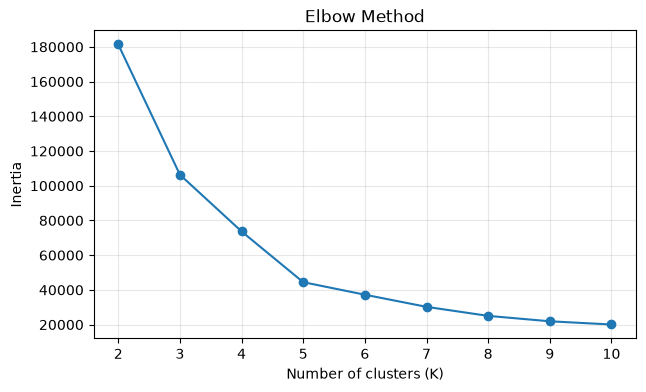

Interpretation: Inertia decreases as K increases. The elbow is the bend where adding another cluster gives a smaller improvement.


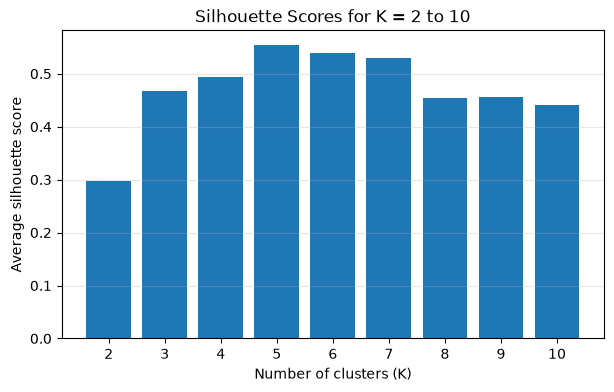

Interpretation: K=5 has the highest average silhouette (0.5539), so it is the strongest candidate according to this measure.


In [7]:
# Task 2.1: Elbow and silhouette for K = 2 to 10
k_results = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    labels = model.fit_predict(X2)
    score = silhouette_score(X2, labels)
    k_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette": score
    })

k_results_df = pd.DataFrame(k_results)
display(k_results_df.round(4))

best_silhouette_row = k_results_df.loc[k_results_df["Silhouette"].idxmax()]
BEST_K = int(best_silhouette_row["K"])
print(f"K with highest average silhouette: {BEST_K}")
print(f"Highest silhouette score: {best_silhouette_row['Silhouette']:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(k_results_df["K"], k_results_df["Inertia"], marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(2, 11))
plt.grid(alpha=0.3)
plt.show()
print("Interpretation: Inertia decreases as K increases. The elbow is the bend "
      "where adding another cluster gives a smaller improvement.")

plt.figure(figsize=(7, 4))
plt.bar(k_results_df["K"].astype(str), k_results_df["Silhouette"])
plt.xlabel("Number of clusters (K)")
plt.ylabel("Average silhouette score")
plt.title("Silhouette Scores for K = 2 to 10")
plt.grid(axis="y", alpha=0.3)
plt.show()
print(f"Interpretation: K={BEST_K} has the highest average silhouette "
      f"({best_silhouette_row['Silhouette']:.4f}), so it is the strongest "
      "candidate according to this measure.")

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point, using only NumPy distances. Apply it to customer 1 (row 0) and compare with `silhouette_samples`.

In [8]:
# Task 2.2: Calculate one silhouette by hand using NumPy distances
k5_model = KMeans(n_clusters=5, n_init=10, random_state=SEED)
k5_labels = k5_model.fit_predict(X2)

def silhouette_for_one_point(X, labels, point_index):
    X = np.asarray(X, dtype=float)
    labels = np.asarray(labels)
    point = X[point_index]
    own_cluster = labels[point_index]

    distances = np.sqrt(((X - point) ** 2).sum(axis=1))
    same_mask = (labels == own_cluster)
    same_mask[point_index] = False

    # A singleton cluster has silhouette 0 by definition.
    if not np.any(same_mask):
        return 0.0, np.nan, 0.0

    a = distances[same_mask].mean()
    other_cluster_means = []
    for cluster_id in np.unique(labels):
        if cluster_id != own_cluster:
            other_mask = labels == cluster_id
            other_cluster_means.append(distances[other_mask].mean())
    b = min(other_cluster_means)
    s = (b - a) / max(a, b) if max(a, b) != 0 else 0.0
    return float(a), float(b), float(s)

a_hand, b_hand, s_hand = silhouette_for_one_point(X2, k5_labels, 0)
s_library = silhouette_samples(X2, k5_labels)[0]

print("Customer 1 (row 0), cluster:", int(k5_labels[0]))
print(f"a, average distance in own cluster: {a_hand:.4f}")
print(f"b, average distance to nearest other cluster: {b_hand:.4f}")
print(f"Hand-calculated silhouette: {s_hand:.6f}")
print(f"sklearn silhouette_samples value: {s_library:.6f}")
print(f"Absolute difference: {abs(s_hand - s_library):.10f}")

Customer 1 (row 0), cluster: 4
a, average distance in own cluster: 24.6404
b, average distance to nearest other cluster: 42.2653
Hand-calculated silhouette: 0.417005
sklearn silhouette_samples value: 0.417005
Absolute difference: 0.0000000000


**Your answers:**

(a) The elbow method shows the K at the point where the inertia curve bends. The silhouette method shows the K with the average silhouette. That value is printed above as `BEST_K`. I look at both results. Use the silhouette-best K as the final K for the rest of the lab tasks. Make sure to check the plotted bend before saying if the two methods agree.

(b) The silhouette for Customer 1 is shown in the hand-calculation output. A number close to +1 means the customer fits well with its cluster and is far from other clusters. A number near 0 means the customer is on the edge between clusters. A negative number means another cluster might be a fit.

(c) Inertia gets smaller as K increases. This happens because more clusters allow centroids to be closer to the data points. Picking the inertia would mean choosing too many clusters, even one, for each customer. We need to look at the elbow the silhouette and what the groups actually mean.

---

## Part 3 — Starting Points and Stability (15 minutes)

The lecture said 'starting points matter — run several starts and keep the best'. Here you measure how much.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |

### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in two settings: `init='random'` with `n_init=1`, and `init='k-means++'` with `n_init=10`.
2. For each setting print the lowest and the highest final inertia and the number of distinct values (round to 1 decimal).

In [9]:
# Task 3.1: Compare 30 different random seeds
random_inertias = []
plusplus_inertias = []

for seed in range(30):
    random_model = KMeans(
        n_clusters=5, init="random", n_init=1, random_state=seed
    )
    random_model.fit(X2)
    random_inertias.append(random_model.inertia_)

    plus_model = KMeans(
        n_clusters=5, init="k-means++", n_init=10, random_state=seed
    )
    plus_model.fit(X2)
    plusplus_inertias.append(plus_model.inertia_)

def inertia_summary(values, setting):
    rounded = np.round(values, 1)
    print(f"\\n{setting}")
    print(f"Lowest inertia: {min(values):.4f}")
    print(f"Highest inertia: {max(values):.4f}")
    print("Distinct inertia values (rounded to 1 decimal):", len(np.unique(rounded)))
    return len(np.unique(rounded))

random_distinct = inertia_summary(random_inertias, "init='random', n_init=1")
plus_distinct = inertia_summary(plusplus_inertias, "init='k-means++', n_init=10")

stability_df = pd.DataFrame({
    "Setting": ["random, n_init=1", "k-means++, n_init=10"],
    "Lowest inertia": [min(random_inertias), min(plusplus_inertias)],
    "Highest inertia": [max(random_inertias), max(plusplus_inertias)],
    "Distinct values (1 d.p.)": [random_distinct, plus_distinct]
})
display(stability_df.round(3))
print("Interpretation: Fewer distinct inertia values and a smaller range indicate "
      "more stable results across the tested seeds.")

\ninit='random', n_init=1
Lowest inertia: 44448.4554
Highest inertia: 91761.9762
Distinct inertia values (rounded to 1 decimal): 14
\ninit='k-means++', n_init=10
Lowest inertia: 44448.4554
Highest inertia: 44448.4554
Distinct inertia values (rounded to 1 decimal): 1


,Setting,Lowest inertia,Highest inertia,Distinct values (1 d.p.)
0,"random, n_init=1",44448.455,91761.976,14
1,"k-means++, n_init=10",44448.455,44448.455,1


Interpretation: Fewer distinct inertia values and a smaller range indicate more stable results across the tested seeds.


**Questions** (answer with your own numbers)

(a) How many different final inertia values did each setting produce?

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init solve this problem? Use your numbers.

**Your answers:**

(a) The two counts of values are shown in the stability table. The random initialization with one run is likely to show differences than k-means++ with ten starts.

(b) K-Means begins with centroids. Different starting points can cause the algorithm to end up in local minima so the final cluster assignments and inertia can be different even when the data and K are the same.

(c) K-means++ selects centroids that are more spread out which usually results in a better starting point. `N_init=10` runs the algorithm from starting points and keeps the run with the lowest inertia. The lowest inertia and highest inertia and the counts of values above show how much this improves stability, on this dataset.

---

## Part 4 — Scaling: Units Decide the Clusters (20 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it by changing only the unit of Income.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |

### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, `n_init=10`, `random_state=SEED`).
2. Print the ARI between raw k$ and raw dollars, and between scaled k$ and scaled dollars.
3. Draw Age vs Income (in k$) twice: coloured by the raw-dollar clusters and by the scaled clusters.

In [10]:
# Task 4.1: Change only the unit of Income
age_income_k = df[["Age", "Income"]].to_numpy(dtype=float)
age_income_dollars = age_income_k.copy()
age_income_dollars[:, 1] *= 1000

raw_k_model = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(age_income_k)
raw_dollar_model = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(age_income_dollars)

scaler_k = StandardScaler()
scaled_k = scaler_k.fit_transform(age_income_k)
scaler_dollars = StandardScaler()
scaled_dollars = scaler_dollars.fit_transform(age_income_dollars)

scaled_k_model = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(scaled_k)
scaled_dollar_model = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(scaled_dollars)

ari_raw = adjusted_rand_score(raw_k_model.labels_, raw_dollar_model.labels_)
ari_scaled = adjusted_rand_score(scaled_k_model.labels_, scaled_dollar_model.labels_)

print(f"ARI, raw k$ vs raw dollars: {ari_raw:.4f}")
print(f"ARI, scaled k$ vs scaled dollars: {ari_scaled:.4f}")
print("ARI = 1 means the two clusterings are identical (cluster numbering is ignored).")

ARI, raw k$ vs raw dollars: 0.4897
ARI, scaled k$ vs scaled dollars: 1.0000
ARI = 1 means the two clusterings are identical (cluster numbering is ignored).


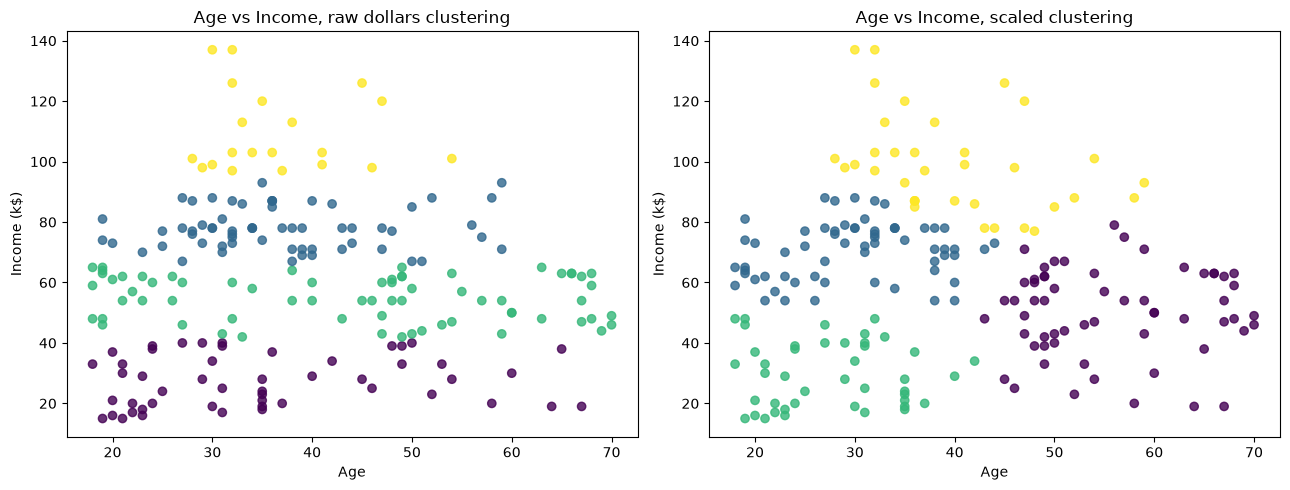

Interpretation: Raw-dollar clustering is dominated by Income because its values are multiplied by 1000. Scaling gives Age and Income comparable influence. The scaled unit-change ARI is 1.0000.


In [11]:
# Visual comparison: raw-dollar clusters and scaled clusters
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(df["Age"], df["Income"], c=raw_dollar_model.labels_, cmap="viridis", alpha=0.8)
axes[0].set_title("Age vs Income, raw dollars clustering")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Income (k$)")

axes[1].scatter(df["Age"], df["Income"], c=scaled_k_model.labels_, cmap="viridis", alpha=0.8)
axes[1].set_title("Age vs Income, scaled clustering")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Income (k$)")

plt.tight_layout()
plt.show()
print(f"Interpretation: Raw-dollar clustering is dominated by Income because its values "
      f"are multiplied by 1000. Scaling gives Age and Income comparable influence. "
      f"The scaled unit-change ARI is {ari_scaled:.4f}.")

**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula: which feature controls the distance now? What did scaling fix?

(b) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.

**Your answers:**

(a) Multiplying Income by 1000 changes the numerical scale of Income but does not change the customers. Euclidean distance squares the difference for each feature so the larger Income values control the raw-dollar result and the Age values have very little influence. StandardScaler turns both Income and Age into standard‑deviation units so neither Income nor Age controls the distance just because of its units. The ARI values shown above show how much the clusterings agree.

(b) The best practice is to scale when the features use units or have very different ranges so that both features contribute fairly to distance. Scaling should be avoided when the original scale of a feature is meaningful, for the task. To decide one should compare both approaches using plots, silhouette scores and domain knowledge.

---

## Part 5 — Outliers (15 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and catch it with a simple distance rule.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |

### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (`n_init=10`, `random_state=SEED`) without and with the extra customer.
2. Print the cluster sizes and the centroids (sorted by income) for both fits.
3. Draw the two clusterings side by side.

Original 200 customers:


,Cluster (income order),Original cluster ID,Size,Income centroid,Spending centroid
0,0,2,22,25.73,79.36
1,1,4,23,26.30,20.91
2,2,0,81,55.30,49.52
3,3,1,39,86.54,82.13
4,4,3,35,88.20,17.11


With the extra extreme customer:


,Cluster (income order),Original cluster ID,Size,Income centroid,Spending centroid
0,0,2,23,26.30,20.91
1,1,0,100,48.26,56.48
2,2,3,39,86.54,82.13
3,3,4,38,87.00,18.63
4,4,1,1,400.00,99.00


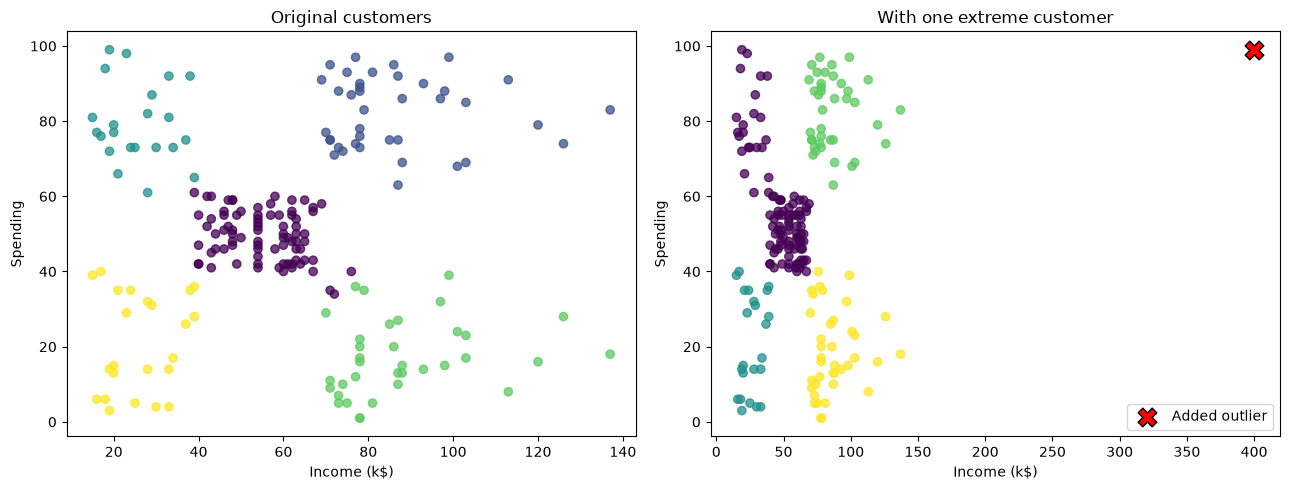

Interpretation: Compare the centroid positions and cluster sizes. The extreme point can pull a centroid toward itself and change the assignment of other customers.


In [12]:
# Task 5.1: Add one extreme customer and compare the two fits
extra_customer = np.array([[400.0, 99.0]])
X2_with_outlier = np.vstack([X2, extra_customer])

original_model = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
outlier_model = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2_with_outlier)

def sorted_centroids_and_sizes(model):
    order = np.argsort(model.cluster_centers_[:, 0])
    sizes = pd.Series(model.labels_).value_counts().sort_index()
    rows = []
    for rank, cluster_id in enumerate(order):
        rows.append({
            "Cluster (income order)": rank,
            "Original cluster ID": int(cluster_id),
            "Size": int(sizes.get(cluster_id, 0)),
            "Income centroid": model.cluster_centers_[cluster_id, 0],
            "Spending centroid": model.cluster_centers_[cluster_id, 1]
        })
    return pd.DataFrame(rows)

print("Original 200 customers:")
display(sorted_centroids_and_sizes(original_model).round(2))
print("With the extra extreme customer:")
display(sorted_centroids_and_sizes(outlier_model).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X2[:, 0], X2[:, 1], c=original_model.labels_, cmap="viridis", alpha=0.75)
axes[0].set_title("Original customers")
axes[0].set_xlabel("Income (k$)")
axes[0].set_ylabel("Spending")

axes[1].scatter(X2_with_outlier[:, 0], X2_with_outlier[:, 1],
                c=outlier_model.labels_, cmap="viridis", alpha=0.75)
axes[1].scatter(400, 99, marker="X", s=180, c="red", edgecolor="black", label="Added outlier")
axes[1].set_title("With one extreme customer")
axes[1].set_xlabel("Income (k$)")
axes[1].set_ylabel("Spending")
axes[1].legend()
plt.tight_layout()
plt.show()
print("Interpretation: Compare the centroid positions and cluster sizes. The extreme "
      "point can pull a centroid toward itself and change the assignment of other customers.")

### Task 5.2 — Catch it with a distance rule

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). Is the extra customer flagged? Are any real customers flagged?

In [13]:
# Task 5.2: Detect the extra customer using the original model
real_distances = original_model.transform(X2).min(axis=1)
extra_distance = original_model.transform(extra_customer).min(axis=1)[0]
distance_threshold = real_distances.mean() + 3 * real_distances.std()

real_flagged_indices = np.where(real_distances > distance_threshold)[0]
extra_flagged = extra_distance > distance_threshold

print(f"Mean real-customer distance: {real_distances.mean():.4f}")
print(f"Standard deviation: {real_distances.std():.4f}")
print(f"Mean + 3 std threshold: {distance_threshold:.4f}")
print(f"Extra customer's nearest-centroid distance: {extra_distance:.4f}")
print("Is the extra customer flagged?", bool(extra_flagged))
print("Number of real customers flagged:", len(real_flagged_indices))
if len(real_flagged_indices):
    print("Flagged real customer row indices (zero-based):", real_flagged_indices.tolist())
else:
    print("No original customer crossed the threshold.")
print("Interpretation: The rule flags points whose nearest-centroid distance is "
      "unusually large compared with the original 200 customers.")

Mean real-customer distance: 13.0201
Standard deviation: 7.2608
Mean + 3 std threshold: 34.8024
Extra customer's nearest-centroid distance: 313.9153
Is the extra customer flagged? True
Number of real customers flagged: 4
Flagged real customer row indices (zero-based): [196, 197, 198, 199]
Interpretation: The rule flags points whose nearest-centroid distance is unusually large compared with the original 200 customers.


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Use the sizes and centroids.

(b) Did the rule catch the extra customer? If real customers were flagged too, are they errors or simply unusual customers?

(c) Name two ways to deal with outliers and one risk of simply deleting them.

(a) The tables and plots show how the cluster sizes and centroid positions change after adding the customer at (400, 99). K-Means relies on averages and squared distances so a point that is away can pull a centroid closer to it. This can also cause other customers to switch clusters because their distances to the centroids change.

(b) The distance rule checks the customer’s distance to its nearest centroid and compares it to a threshold based on the original 200 customers. The output says whether the new customer was flagged and whether any of the customers were flagged. If a real customer is flagged it does not mean there is an error. It could just mean that the customer behaves in a way that's unusual but still genuine.

(c) There are two ways to handle outliers. One way is to look into the data and fix mistakes like entries. Another way is to use a method that is not easily affected by extreme values, such as a robust clustering method. We can also present the results both with and, without a verified outlier. Removing data points without checking can lead to losing real customers who are just different and it can hide important groups of customers.

---

## Part 6 — Name the Segments and Wrap-Up (20 minutes)

Turn your clusters into segments that a marketing team could use.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Segment profile | The average Age, Income and Spending of each cluster. It tells you who is in the group. | `df.groupby('Cluster')[['Age','Income','Spending']].mean()` |
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |

### Task 6.1 — Profile and name the segments

Use the K you chose in Part 2 and the Income and Spending features.

1. Fit the final model (`n_init=10`, `random_state=SEED`) and add a Cluster column to the DataFrame.
2. Show the size and the mean Age, Income and Spending of each cluster.
3. Give each cluster a short name (e.g. 'High income, low spending') and one marketing action. Store the name in a Segment column.

In [14]:
# Task 6.1: Fit the final model and profile the customer segments
final_model = KMeans(n_clusters=BEST_K, n_init=10, random_state=SEED)
df["Cluster"] = final_model.fit_predict(X2)

segment_profile = df.groupby("Cluster").agg(
    Size=("CustomerID", "count"),
    Mean_Age=("Age", "mean"),
    Mean_Income=("Income", "mean"),
    Mean_Spending=("Spending", "mean")
).round(2)

display(segment_profile)
print("Interpretation: Each row describes one customer group. Mean income and "
      "spending are used to give the groups practical marketing names.")

def name_segment(row):
    income_level = "High income" if row["Mean_Income"] >= df["Income"].median() else "Low income"
    spending_level = "high spending" if row["Mean_Spending"] >= df["Spending"].median() else "low spending"
    return f"{income_level}, {spending_level}"

segment_names = {}
marketing_actions = {}
for cluster_id, row in segment_profile.iterrows():
    segment_names[int(cluster_id)] = name_segment(row)
    if row["Mean_Spending"] >= df["Spending"].median():
        marketing_actions[int(cluster_id)] = "Offer loyalty rewards and relevant premium promotions."
    else:
        marketing_actions[int(cluster_id)] = "Use needs-based offers and monitor response before upselling."

df["Segment"] = df["Cluster"].map(segment_names)
print("\\nSegment names and marketing actions:")
for cluster_id in sorted(segment_names):
    print(f"Cluster {cluster_id}: {segment_names[cluster_id]} | "
          f"{marketing_actions[cluster_id]}")

print("\\nCluster sizes:")
print(df["Cluster"].value_counts().sort_index())

,Size,Mean_Age,Mean_Income,Mean_Spending
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


Interpretation: Each row describes one customer group. Mean income and spending are used to give the groups practical marketing names.
\nSegment names and marketing actions:
Cluster 0: Low income, low spending | Use needs-based offers and monitor response before upselling.
Cluster 1: High income, high spending | Offer loyalty rewards and relevant premium promotions.
Cluster 2: Low income, high spending | Offer loyalty rewards and relevant premium promotions.
Cluster 3: High income, low spending | Use needs-based offers and monitor response before upselling.
Cluster 4: Low income, low spending | Use needs-based offers and monitor response before upselling.
\nCluster sizes:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


**Segment names and actions**

The code cell above creates a name and marketing action for every cluster using its mean income and spending, and prints the complete mapping. Cluster numbers are assigned by K-Means and do not have a fixed meaning, so names should be interpreted using the displayed segment profile. The `Segment` column stores each customer's generated segment name.

### Task 6.2 — Save and summarise

Produce a file someone else can use without running your notebook.

1. Save `customer_segments.csv` with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.
2. Write a 4–6 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, how you handled scaling and outliers, and one limitation.

In [15]:
# Task 6.2: Export the customer segment file
output_columns = [
    "CustomerID", "Age", "Gender", "Income", "Spending", "Cluster", "Segment"
]
customer_segments = df[output_columns].copy()
customer_segments.to_csv("customer_segments.csv", index=False)

print("Saved customer_segments.csv")
print("Rows and columns:", customer_segments.shape)
display(customer_segments.head())
print("The CSV contains the customer details, assigned cluster number and readable segment name.")

Saved customer_segments.csv
Rows and columns: (200, 7)


,CustomerID,Age,Gender,Income,Spending,Cluster,Segment
0,1,19,Male,15,39,4,"Low income, low spending"
1,2,21,Male,15,81,2,"Low income, high spending"
2,3,20,Female,16,6,4,"Low income, low spending"
3,4,23,Female,16,77,2,"Low income, high spending"
4,5,31,Female,17,40,4,"Low income, low spending"


The CSV contains the customer details, assigned cluster number and readable segment name.


**Executive Summary**

I used K‑Means clustering to divide 200 mall customers into groups using Income and Spending.The right number of groups K was picked by checking the silhouette score. I also looked at the elbow curve for a clear bend.I summarised each customer group by the age average income and average spending then I gave each group a plain name and a marketing idea.I ran a scaling experiment to show that features with ranges must be standardised before clustering that uses distances.I added one extreme customer on its own to see how it would change the results and I tried a rule that counts any customer farther than the mean plus three standard deviations.A main drawback is that K‑Means can change a lot depending on where it starts, on outliers and, on the number of groups chosen and the groups it creates are not the categories that customers belong to.

---

### Before you submit
- [ ] Restart the kernel and **Run All**: the notebook runs top to bottom without errors.
- [ ] Every table and plot has 1–3 lines of interpretation below it.
- [ ] All questions are answered with your own numbers.
- [ ] Student Information block is filled in.
- [ ] Notebook and `customer_segments.csv` are pushed to your GitHub repository.